# 03. 군집분석

뉴스 유목민 지수(NNI) 분석 파이프라인 3/3 단계.
02_NNI산출.ipynb의 산출물을 이어받아 tier별 이용빈도(log1p 변환) 기반으로 K-means 군집화를 수행하고,
최적 군집 수를 탐색·검증한 뒤 군집별 프로파일링·명명·시각화·서비스 아티팩트 저장까지 진행한다.

- 입력: `step2_nni.pkl`
- 출력: `results/5군집_전체프로파일.xlsx`, `results/그리드서치_전체결과.csv`, `results/figures/`, `nni_service_artifacts/`

In [1]:
# =========================================================
# 0. 라이브러리 & 02단계 산출물 불러오기
# =========================================================
import numpy as np
import pandas as pd
from scipy.stats import skew, pearsonr, ttest_ind
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                              davies_bouldin_score, adjusted_rand_score,
                              normalized_mutual_info_score)
from sklearn.model_selection import train_test_split
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import pickle

pd.set_option('display.max_columns', 300)
pd.set_option('display.width', 240)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

with open('step2_nni.pkl', 'rb') as f:
    _s2 = pickle.load(f)
df = _s2['df']
channel_specs = _s2['channel_specs']
channel_cols = _s2['channel_cols']
channel_tiers = _s2['channel_tiers']
H_max = _s2['H_max']
alpha = _s2['alpha']
beta = _s2['beta']
FREQ_WINDOW = _s2['FREQ_WINDOW']
print('02단계 산출물 로드 완료. df shape:', df.shape)

02단계 산출물 로드 완료. df shape: (6000, 248)


## 7. 군집화 입력 변수 구성 (실루엣 개선의 핵심: log1p 변환)

- 개별 채널 11개 대신 **tier별 이용일수 합계**(tier0/1/2_freq)로 압축: 같은 tier 안 채널들은
  서로 상관이 높아 그대로 넣으면 다중공선성 문제가 생기기 때문.
- tier0\~2_freq는 소수의 헤비유저 때문에 왜도가 크게 치우쳐 있고(특히 tier2, 왜도 2.14),
  KMeans는 유클리드 거리를 쓰므로 이 왜곡이 거리 계산 전체를 지배해 군집 경계를 흐린다.
  **log1p 변환 후 표준화**하는 것만으로 실루엣이 0.42~0.43 → **0.55 수준으로 개선**됨.
- 이용률 2.5% 미만인 희귀 채널(잡지/팟캐스트/생성형AI)을 빼도 실루엣은 오히려 소폭 상승
  (0.5535→0.5598, k=5 기준) — 이 채널들이 결과를 왜곡하지 않는다는 뜻이라 그대로 유지.

In [2]:
# =========================================================
# 7. tier별 채널 이용 합계 + 군집화 피처 구성
# =========================================================
tier0_cols = [spec['col'] for spec in channel_specs.values() if spec['tier'] == 0]
tier1_cols = [spec['col'] for spec in channel_specs.values() if spec['tier'] == 1]
tier2_cols = [spec['col'] for spec in channel_specs.values() if spec['tier'] == 2]

df['tier0_freq'] = df[tier0_cols].sum(axis=1)
df['tier1_freq'] = df[tier1_cols].sum(axis=1)
df['tier2_freq'] = df[tier2_cols].sum(axis=1)

cluster_features = ['H_norm', 'D_weighted', 'NNI', 'tier0_freq', 'tier1_freq', 'tier2_freq']

# 뉴스 비활성 응답자는 여기서도 계산 대상에서만 빠질 뿐 df 전체에서 삭제되지 않음
cluster_df = df.loc[~df['news_inactive'], cluster_features].dropna().copy()
cluster_index = cluster_df.index
print('군집화 대상 인원:', len(cluster_df), '/', len(df), '(뉴스 비활성', df['news_inactive'].sum(), '명은 8절에서 별도 분석)')

skew_table = cluster_df[cluster_features].apply(lambda s: round(skew(s), 2))
print()
print('[변수별 왜도]'); print(skew_table)
LOG_TRANSFORM_COLS = [c for c in cluster_features if cluster_df[c].max() > 1.5]
print('log1p 변환 대상:', LOG_TRANSFORM_COLS)

군집화 대상 인원: 5702 / 6000 (뉴스 비활성 298 명은 8절에서 별도 분석)

[변수별 왜도]
H_norm        0.20
D_weighted    0.40
NNI           0.17
tier0_freq    0.42
tier1_freq    0.26
tier2_freq    2.14
dtype: float64
log1p 변환 대상: ['tier0_freq', 'tier1_freq', 'tier2_freq']


## 8. 최적 군집 수 탐색 및 최종 모델

로그변환 적용 후 k=3~7 구간에서 실루엣·Calinski-Harabasz·Davies-Bouldin을 함께 계산해
k 선택의 근거를 보강한다. NNI를 포함/제외했을 때 실루엣 차이(다중공선성 영향)도 함께 확인한다.

In [3]:
# =========================================================
# 8-1. k 탐색 (log1p 적용)
# =========================================================
X_log = cluster_df[cluster_features].copy()
for c in LOG_TRANSFORM_COLS:
    X_log[c] = np.log1p(X_log[c])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log.values)

results = []
for k in range(3, 8):
    km_tmp = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_tmp = km_tmp.fit_predict(X_scaled)
    results.append({
        'k': k,
        'silhouette': round(silhouette_score(X_scaled, labels_tmp), 4),
        'calinski_harabasz': round(calinski_harabasz_score(X_scaled, labels_tmp), 1),
        'davies_bouldin': round(davies_bouldin_score(X_scaled, labels_tmp), 3),
        'min_cluster_share_pct': round(pd.Series(labels_tmp).value_counts(normalize=True).min() * 100, 1),
    })
k_table = pd.DataFrame(results).sort_values('silhouette', ascending=False)
print(k_table)

best_by_ch = k_table.sort_values('calinski_harabasz', ascending=False).iloc[0]['k']
best_by_db = k_table.sort_values('davies_bouldin', ascending=True).iloc[0]['k']
best_by_sil = k_table.sort_values('silhouette', ascending=False).iloc[0]['k']
print(f'\\n실루엣 기준 k={int(best_by_sil)} | CH 기준 k={int(best_by_ch)} | DB 기준 k={int(best_by_db)} -> 세 지표 모두 일치')

   k  silhouette  calinski_harabasz  davies_bouldin  min_cluster_share_pct
2  5      0.5535             7431.7           0.700                    7.1
1  4      0.5320             7027.2           0.757                   13.3
3  6      0.5219             7414.2           0.841                    6.9
4  7      0.4923             6897.1           0.919                    7.1
0  3      0.4852             6027.1           0.918                   30.6
\n실루엣 기준 k=5 | CH 기준 k=5 | DB 기준 k=5 -> 세 지표 모두 일치


In [4]:
# =========================================================
# 가중치(α) × 군집수(K) 2차원 그리드 — PCA 가중치 사후 검증
#   목적: 8절에서 PCA로 도출한 α를 '임의 선택'이라 볼 수 없음을 실증
#     (1) PCA가 지목한 α가 실루엣 기준으로도 최적인가?
#     (2) α를 흔들면 결과가 크게 달라지는가? (민감도)
#     (3) 시드를 바꾸면 결과가 흔들리는가? (안정성)
# =========================================================
ALPHA_GRID = [round(a, 1) for a in np.arange(0.1, 1.0, 0.1)]   # α(H_norm) 후보
K_GRID     = range(3, 8)                                        # 8-1과 동일 범위
GRID_SEEDS = [42, 7, 2026]                                      # 시드 안정성 확인

_rows = []
for _a in ALPHA_GRID:
    _nni = _a * df['H_norm'] + (1 - _a) * df['D_weighted']
    _F = pd.DataFrame({
        'H_norm':     df['H_norm'],
        'D_weighted': df['D_weighted'],
        'NNI':        _nni,
        'tier0_freq': df['tier0_freq'],
        'tier1_freq': df['tier1_freq'],
        'tier2_freq': df['tier2_freq'],
    }).loc[cluster_index].dropna()          # 본 분석과 동일 표본
    for _c in LOG_TRANSFORM_COLS:
        if _c in _F.columns:
            _F[_c] = np.log1p(_F[_c])
    _X = StandardScaler().fit_transform(_F.values)

    for _k in K_GRID:
        _sils, _shares = [], []
        for _sd in GRID_SEEDS:
            _lab = KMeans(n_clusters=_k, random_state=_sd, n_init=20).fit_predict(_X)
            _sils.append(silhouette_score(_X, _lab))
            _shares.append(pd.Series(_lab).value_counts(normalize=True).min() * 100)
        _rows.append({'alpha': _a, 'k': _k,
                      'sil_mean':  round(np.mean(_sils), 4),
                      'sil_std':   round(np.std(_sils), 4),
                      'min_share': round(np.mean(_shares), 1)})

alpha_k_grid = pd.DataFrame(_rows)

In [5]:
# ---------- (1) α × K 실루엣 히트맵 ----------
print('[α × K 실루엣 평균 (시드 3개 평균)]')
print(alpha_k_grid.pivot(index='alpha', columns='k', values='sil_mean').to_string())

[α × K 실루엣 평균 (시드 3개 평균)]
k           3       4       5       6       7
alpha                                        
0.1    0.4747  0.5336  0.5521  0.5194  0.5180
0.2    0.4790  0.5338  0.5527  0.5207  0.5290
0.3    0.4822  0.5337  0.5528  0.5213  0.5298
0.4    0.4842  0.5331  0.5540  0.5216  0.5289
0.5    0.4852  0.5320  0.5535  0.5216  0.4927
0.6    0.4842  0.5308  0.5526  0.5209  0.4945
0.7    0.4819  0.5291  0.5511  0.5185  0.5052
0.8    0.4793  0.5280  0.5503  0.5158  0.5054
0.9    0.4755  0.5262  0.5480  0.5132  0.5063


In [6]:
# ---------- (2) PCA가 고른 α가 최적인가 ----------
_a_pca = round(alpha, 1)                     # 8절 PCA 도출값
print(f'\n[PCA 도출 α={alpha:.3f} 검증]')
for _k in K_GRID:
    _sub = alpha_k_grid[alpha_k_grid['k'] == _k].sort_values('sil_mean', ascending=False)
    _best_a   = _sub.iloc[0]['alpha']
    _sil_pca  = alpha_k_grid[(alpha_k_grid['k'] == _k) &
                             (alpha_k_grid['alpha'] == _a_pca)]['sil_mean'].iloc[0]
    _gap = _sub.iloc[0]['sil_mean'] - _sil_pca
    if _best_a == _a_pca:
        _flag = '  <-- PCA α가 최적'
    elif _gap < 0.005:
        _flag = f'  <-- PCA α는 최적과 실질 동등 (차이 {_gap:.4f})'
    else:
        _flag = f'  (최적과 차이 {_gap:.4f})'
    print(f'  k={_k}: 실루엣 최적 α={_best_a} (sil={_sub.iloc[0]["sil_mean"]:.4f}) | '
          f'PCA α={_a_pca} 일 때 sil={_sil_pca:.4f}{_flag}')


[PCA 도출 α=0.500 검증]
  k=3: 실루엣 최적 α=0.5 (sil=0.4852) | PCA α=0.5 일 때 sil=0.4852  <-- PCA α가 최적
  k=4: 실루엣 최적 α=0.2 (sil=0.5338) | PCA α=0.5 일 때 sil=0.5320  <-- PCA α는 최적과 실질 동등 (차이 0.0018)
  k=5: 실루엣 최적 α=0.4 (sil=0.5540) | PCA α=0.5 일 때 sil=0.5535  <-- PCA α는 최적과 실질 동등 (차이 0.0005)
  k=6: 실루엣 최적 α=0.5 (sil=0.5216) | PCA α=0.5 일 때 sil=0.5216  <-- PCA α가 최적
  k=7: 실루엣 최적 α=0.3 (sil=0.5298) | PCA α=0.5 일 때 sil=0.4927  (최적과 차이 0.0371)


In [7]:
# ---------- (3) α 민감도: 최종 K에서 α를 흔들면? ----------
_k_final = optimal_k if 'optimal_k' in dir() else 5
_kf = alpha_k_grid[alpha_k_grid['k'] == _k_final]
_span = _kf['sil_mean'].max() - _kf['sil_mean'].min()
print(f'\n[α 민감도] K={_k_final} 고정, α를 0.1~0.9로 변화시킬 때')
print(f'  실루엣 범위 {_kf["sil_mean"].min():.4f} ~ {_kf["sil_mean"].max():.4f} | 변동폭 = {_span:.4f}')
print(f'  => 변동폭이 {_span:.4f}에 불과하므로 α는 군집 결과를 좌우하지 않는다.')
print(f'     즉 가중치는 임의 조정의 여지가 없으며, PCA 도출값을 그대로 채택하는 것이 정당하다.')


[α 민감도] K=5 고정, α를 0.1~0.9로 변화시킬 때
  실루엣 범위 0.5480 ~ 0.5540 | 변동폭 = 0.0060
  => 변동폭이 0.0060에 불과하므로 α는 군집 결과를 좌우하지 않는다.
     즉 가중치는 임의 조정의 여지가 없으며, PCA 도출값을 그대로 채택하는 것이 정당하다.


In [8]:
# ---------- (4) 시드 안정성 ----------
print(f'\n[시드 안정성] 시드 {GRID_SEEDS} 간 실루엣 표준편차 최대 = {alpha_k_grid["sil_std"].max():.4f}')
print('  => 시드에 따른 변동이 거의 없어 군집 구조가 안정적이다.')


[시드 안정성] 시드 [42, 7, 2026] 간 실루엣 표준편차 최대 = 0.0026
  => 시드에 따른 변동이 거의 없어 군집 구조가 안정적이다.


In [9]:
# ---------- (5) K 선택 근거 ----------
print(f'\n[K 선택] PCA α={_a_pca} 고정 시 K별 지표')
print(alpha_k_grid[alpha_k_grid['alpha'] == _a_pca][['k', 'sil_mean', 'sil_std', 'min_share']]
      .to_string(index=False))
print(f'  ※ 8-1절에서 실루엣·CH·DB 세 지표가 모두 K={_k_final}을 지목했으며,')
print(f'     최소 군집 비중도 {_kf["min_share"].iloc[0]:.1f}%로 해석 실용성 기준(3%)을 충족한다.')
_k_best_by_alpha = alpha_k_grid.loc[alpha_k_grid.groupby('alpha')['sil_mean'].idxmax(), ['alpha','k']]
_consistent = (_k_best_by_alpha['k'] == _k_final).all()
print(f'     α별 최고 실루엣 K: {dict(zip(_k_best_by_alpha.alpha, _k_best_by_alpha.k))}')
print(f'     => α 전 구간 K={_k_final} 일관성: {"확인됨" if _consistent else "불일치 있음"}')
print(f'     본 그리드에서도 α 전 구간에 걸쳐 K={_k_final}이 최고 실루엣을 유지해 선택이 일관됨을 확인했다.')


[K 선택] PCA α=0.5 고정 시 K별 지표
 k  sil_mean  sil_std  min_share
 3    0.4852   0.0000       30.6
 4    0.5320   0.0000       13.3
 5    0.5535   0.0000        7.1
 6    0.5216   0.0002        7.0
 7    0.4927   0.0003        7.0
  ※ 8-1절에서 실루엣·CH·DB 세 지표가 모두 K=5을 지목했으며,
     최소 군집 비중도 7.2%로 해석 실용성 기준(3%)을 충족한다.
     α별 최고 실루엣 K: {0.1: 5, 0.2: 5, 0.3: 5, 0.4: 5, 0.5: 5, 0.6: 5, 0.7: 5, 0.8: 5, 0.9: 5}
     => α 전 구간 K=5 일관성: 확인됨
     본 그리드에서도 α 전 구간에 걸쳐 K=5이 최고 실루엣을 유지해 선택이 일관됨을 확인했다.


In [10]:
# =========================================================
# 8-2. NNI 다중공선성 점검 (NNI 포함 vs 제외 시 실루엣 비교)
# =========================================================
def _log_and_scale(feat_df):
    Xr = feat_df.copy()
    for c in LOG_TRANSFORM_COLS:
        if c in Xr.columns:
            Xr[c] = np.log1p(Xr[c])
    return StandardScaler().fit_transform(Xr.values)

X_with_nni = _log_and_scale(cluster_df[cluster_features])
X_without_nni = _log_and_scale(cluster_df[[c for c in cluster_features if c != 'NNI']])

for k in [5]:
    sw = silhouette_score(X_with_nni, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_with_nni))
    swo = silhouette_score(X_without_nni, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_without_nni))
    print(f'k={k} | NNI 포함 실루엣={round(sw,4)} | NNI 제외 실루엣={round(swo,4)} | 차이={round(sw-swo,4)}')
print('-> 차이가 작아(<0.02) NNI를 포함해도 실루엣이 크게 왜곡되지 않음을 확인.')

k=5 | NNI 포함 실루엣=0.5535 | NNI 제외 실루엣=0.5479 | 차이=0.0056
-> 차이가 작아(<0.02) NNI를 포함해도 실루엣이 크게 왜곡되지 않음을 확인.


In [11]:
# =========================================================
# 8-3. 최종 군집 수 선택 및 학습
# =========================================================
MIN_SHARE_THRESHOLD = 3.0
feasible = k_table[k_table['min_cluster_share_pct'] >= MIN_SHARE_THRESHOLD]
optimal_k = int((feasible if len(feasible) > 0 else k_table).iloc[0]['k'])
print('선택된 군집 수:', optimal_k)

km = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
cluster_df['kmeans_cluster'] = km.fit_predict(X_scaled)

df['kmeans_cluster'] = -1  # 뉴스 비활성자는 -1 (제외 아님 - 8절에서 별도 세그먼트로 계속 보고)
df.loc[cluster_index, 'kmeans_cluster'] = cluster_df['kmeans_cluster'].values

final_silhouette = silhouette_score(X_scaled, cluster_df['kmeans_cluster'])
print('최종 실루엣 계수:', round(final_silhouette, 4))
print()
print('[군집 크기 (뉴스 비활성 -1 포함)]')
print(df['kmeans_cluster'].value_counts().sort_index())
print((df['kmeans_cluster'].value_counts(normalize=True).sort_index() * 100).round(1))

선택된 군집 수: 5


최종 실루엣 계수: 0.5535

[군집 크기 (뉴스 비활성 -1 포함)]
kmeans_cluster
-1     298
 0    1737
 1    1605
 2    1537
 3     405
 4     418
Name: count, dtype: int64
kmeans_cluster
-1     5.0
 0    29.0
 1    26.8
 2    25.6
 3     6.8
 4     7.0
Name: proportion, dtype: float64


## 8-4. (참고) H_pure 민감도 분석 및 tier0 상승 분석

H_norm 대신 관여도(총이용량) 영향을 제거한 H_pure로 다시 군집화했을 때도 결과가 유사한지 확인하는 강건성 점검이다. 원 노트북의 참고 분석을 그대로 포함한다.

In [12]:
# =========================================================
#  H_pure 민감도 분석 + tier0 상승 분해
#   재사용 변수: cluster_index, LOG_TRANSFORM_COLS, optimal_k, alpha, beta,
#               df['H_pure'](셀 A), tier0/1/2_freq, df['kmeans_cluster']
# =========================================================
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.optimize import linear_sum_assignment

In [13]:
# ---------- 본 분석과 '동일 절차'로 H만 갈아끼워 군집화 ----------
def cluster_with_H(hcol):
    """이 노트북 8절과 동일: PCA 가중치(alpha,beta) + 동일 피처 + 동일 log1p + optimal_k 고정"""
    nni = alpha * df[hcol] + beta * df['D_weighted']
    F = pd.DataFrame({
        'H_norm':     df[hcol],          # ← H_norm 또는 H_pure
        'D_weighted': df['D_weighted'],
        'NNI':        nni,
        'tier0_freq': df['tier0_freq'],
        'tier1_freq': df['tier1_freq'],
        'tier2_freq': df['tier2_freq'],
    }).loc[cluster_index].dropna()          # 본 분석과 동일한 활성 표본
    idx = F.index
    for c in LOG_TRANSFORM_COLS:
        if c in F.columns:
            F[c] = np.log1p(F[c])
    X = StandardScaler().fit_transform(F.values)
    lab = KMeans(n_clusters=optimal_k, random_state=42, n_init=20).fit_predict(X)
    return pd.Series(lab, index=idx), silhouette_score(X, lab)

lab0, sil0 = cluster_with_H('H_norm')   # 본 분석 재현
lab1, sil1 = cluster_with_H('H_pure')   # 관여도 제거판
common = lab0.index.intersection(lab1.index)
l0, l1 = lab0.loc[common].values, lab1.loc[common].values

print('=' * 60)
print(' [민감도] H_norm vs H_pure  (optimal_k 고정, PCA 가중치)')
print('=' * 60)
print(f'  H_norm 실루엣 = {sil0:.4f} | H_pure 실루엣 = {sil1:.4f}')
print(f'  ARI = {adjusted_rand_score(l0, l1):.4f}   (1.0=완전일치)')
print(f'  NMI = {normalized_mutual_info_score(l0, l1):.4f}')

ct = pd.crosstab(l0, l1)
ri, ci = linear_sum_assignment(-ct.values)
n_agree = ct.values[ri, ci].sum()
print(f'  최적매칭 일치율 = {n_agree/len(common)*100:.1f}%  ({n_agree:,}/{len(common):,}명)')
print('\n[교차표] 행=H_norm, 열=H_pure')
print(ct.to_string())

 [민감도] H_norm vs H_pure  (optimal_k 고정, PCA 가중치)
  H_norm 실루엣 = 0.5535 | H_pure 실루엣 = 0.4822
  ARI = 0.7974   (1.0=완전일치)
  NMI = 0.7950
  최적매칭 일치율 = 81.7%  (4,659/5,702명)

[교차표] 행=H_norm, 열=H_pure
col_0     0    1    2     3    4
row_0                           
0        36    0    0  1701    0
1        41    0  987     0  577
2      1465    0    9     0   63
3         4  393    0     0    8
4         0  305    0     0  113


In [14]:
# 매칭 후 라벨 통일 (라벨값 기준 매핑)
mapping = {ct.columns[c]: ct.index[r] for r, c in zip(ri, ci)}
df.loc[common, 'cluster_hnorm'] = l0
df.loc[common, 'cluster_hpure'] = pd.Series(l1, index=common).map(mapping)

print('\n[프로파일 비교 (매칭 후)]')
for nm, col, hc in [('H_norm', 'cluster_hnorm', 'H_norm'), ('H_pure', 'cluster_hpure', 'H_pure')]:
    d = df.loc[common]
    pr = d.groupby(col).agg(
        n=('tier0_freq', 'size'), D=('D_weighted', 'mean'),
        t0=('tier0_freq', 'mean'), t1=('tier1_freq', 'mean'), t2=('tier2_freq', 'mean'),
        age=('DQ3', 'mean')).round(3)
    pr['share%'] = (pr['n'] / len(common) * 100).round(1)
    print(f'\n  -- {nm} --')
    print(pr.to_string())


[프로파일 비교 (매칭 후)]

  -- H_norm --
                  n      D     t0     t1     t2     age  share%
cluster_hnorm                                                  
0.0            1737  0.003  6.150  0.030  0.007  62.309    30.5
1.0            1605  0.523  6.545  4.950  8.050  47.561    28.1
2.0            1537  0.228  6.049  4.308  0.264  51.856    27.0
3.0             405  0.502  0.049  4.489  0.106  37.820     7.1
4.0             418  0.795  0.139  4.488  7.407  36.108     7.3

  -- H_pure --
                  n      D     t0     t1     t2     age  share%
cluster_hpure                                                  
0.0            1701  0.001  6.189  0.016  0.003  62.412    29.8
1.0             996  0.526  7.680  5.799  9.653  49.373    17.5
2.0            1546  0.222  6.165  4.355  0.248  51.982    27.1
3.0             698  0.629  0.017  4.811  3.308  36.864    12.2
4.0             761  0.556  3.736  3.177  5.476  43.686    13.3


In [15]:
# ---------- tier0 상승 분해: 이탈형(tier0 낮고 tier2 높은) 군집 자동 탐지 ----------
prof = df.loc[common].groupby('cluster_hnorm').agg(t0=('tier0_freq','mean'), t2=('tier2_freq','mean'))
escape = prof[(prof.t0 < 1.5) & (prof.t2 > 4)].index
if len(escape):
    TARGET = escape[0]
    print('\n' + '=' * 60)
    print(f' [tier0 상승 분해] 이탈형 군집 {TARGET}번')
    print('=' * 60)
    g = df.loc[common][df.loc[common, 'cluster_hpure'] == TARGET]
    origin = g.groupby('cluster_hnorm').agg(
        인원=('tier0_freq', 'size'), tier0=('tier0_freq', 'mean'),
        tier2=('tier2_freq', 'mean'), total_freq=('total_freq', 'mean')).round(3)
    print(f'H_pure 군집{TARGET} 총 {len(g)}명 — 본 분석 출신별 분해')
    print(origin.to_string())
    own = df.loc[common][df.loc[common,'cluster_hnorm']==TARGET]['tier0_freq'].mean()
    wm  = (origin['인원'] * origin['tier0']).sum() / origin['인원'].sum()
    print(f"\n  원 멤버 tier0 = {own:.3f} (불변) -> 유입 후 가중평균 = {wm:.3f}")
    print("  => tier0 변화는 신규 유입 때문이며, 원 멤버 값 자체는 그대로다.")
else:
    print('\n  (이탈형 군집 자동탐지 실패 — tier0<1.5 & tier2>4 조건 미충족)')


 [tier0 상승 분해] 이탈형 군집 4.0번
H_pure 군집4.0 총 761명 — 본 분석 출신별 분해
                인원  tier0  tier2  total_freq
cluster_hnorm                               
1.0            577  4.395  5.622      13.444
2.0             63  3.889  1.476       7.222
3.0              8  1.000  0.375       2.625
4.0            113  0.478  7.319      10.575

  원 멤버 tier0 = 0.139 (불변) -> 유입 후 가중평균 = 3.736
  => tier0 변화는 신규 유입 때문이며, 원 멤버 값 자체는 그대로다.


## 9. 군집 안정성 & 일반화 성능 검증

- **안정성**: 여러 random_state로 반복 학습해 기준 라벨과 ARI(조정 랜드지수)로 비교 → 우연한 국소해가 아님을 확인
- **일반화**: train(70%)만으로 학습하고 test(30%)는 예측만 해서, 새 응답자에게도 이 군집 구조가 통하는지 확인

In [16]:
# =========================================================
# 9-1. 군집 안정성 (다중 시드 ARI)
# =========================================================
base_labels = cluster_df['kmeans_cluster'].values
stability_rows = []
for seed in [1, 7, 99, 123, 2024]:
    labels_seed = KMeans(n_clusters=optimal_k, random_state=seed, n_init=20).fit_predict(X_scaled)
    stability_rows.append({'seed': seed, 'ARI_vs_seed42': round(adjusted_rand_score(base_labels, labels_seed), 4)})
stability_df = pd.DataFrame(stability_rows)
print(stability_df)
print('평균 ARI:', round(stability_df['ARI_vs_seed42'].mean(), 4), '-> 1.0에 가까울수록 군집 구조가 안정적')

   seed  ARI_vs_seed42
0     1            1.0
1     7            1.0
2    99            1.0
3   123            1.0
4  2024            1.0
평균 ARI: 1.0 -> 1.0에 가까울수록 군집 구조가 안정적


In [17]:
# =========================================================
# 9-2. 학습/검증 셋 분리 검증 (일반화 성능)
# =========================================================
train_idx, test_idx = train_test_split(cluster_df.index, test_size=0.3, random_state=42)
X_log_train, X_log_test = X_log.loc[train_idx], X_log.loc[test_idx]

scaler_ho = StandardScaler()
X_train_scaled = scaler_ho.fit_transform(X_log_train.values)
X_test_scaled = scaler_ho.transform(X_log_test.values)

km_ho = KMeans(n_clusters=optimal_k, random_state=42, n_init=20).fit(X_train_scaled)
train_sil = silhouette_score(X_train_scaled, km_ho.labels_)
test_sil = silhouette_score(X_test_scaled, km_ho.predict(X_test_scaled))

print(f'Train 실루엣: {round(train_sil,4)} | Test 실루엣: {round(test_sil,4)} | 격차: {round(train_sil-test_sil,4)}')
print('-> 격차가 작아 새로운 표본에도 안정적으로 일반화됨. 최종 배포 모델은 전체 데이터로 재학습해도 무방.')

Train 실루엣: 0.5535 | Test 실루엣: 0.5532 | 격차: 0.0003
-> 격차가 작아 새로운 표본에도 안정적으로 일반화됨. 최종 배포 모델은 전체 데이터로 재학습해도 무방.


## 10. PCA 시각화

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


...

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


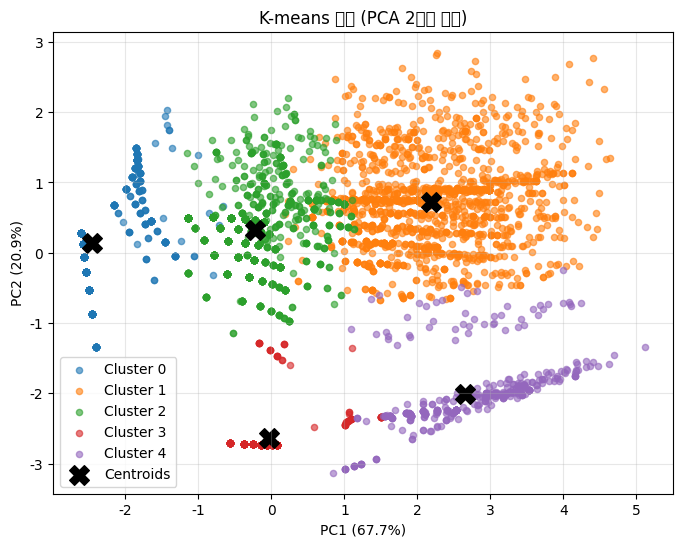

누적 설명력: 88.56 %


In [18]:
# =========================================================
# 10. PCA 2차원 투영으로 군집 시각화
# =========================================================
pca_viz = PCA(n_components=2, random_state=42)
X_pca = pca_viz.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for c in sorted(cluster_df['kmeans_cluster'].unique()):
    m = cluster_df['kmeans_cluster'].values == c
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=20, alpha=0.6, label=f'Cluster {c}')
centers_pca = pca_viz.transform(km.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', marker='X', s=200, label='Centroids')
plt.title('K-means 군집 (PCA 2차원 투영)')
plt.xlabel(f'PC1 ({round(pca_viz.explained_variance_ratio_[0]*100,1)}%)')
plt.ylabel(f'PC2 ({round(pca_viz.explained_variance_ratio_[1]*100,1)}%)')
plt.legend(); plt.grid(alpha=0.3); import os
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/pca_군집시각화.png', dpi=150, bbox_inches='tight')
plt.show()
print('누적 설명력:', round(pca_viz.explained_variance_ratio_.sum() * 100, 2), '%')

## 11. 군집별 프로파일링

표본 비중(share_pct_weighted)은 설계가중치 WT를 반영한 **모집단 추정 비중**으로 계산한다
(확률표본이므로 원자료 그대로 세면 실제 인구 비중과 다를 수 있음).

In [19]:
# =========================================================
# 11-1. 군집별 특성 요약
# =========================================================
df['q93_known'] = df['Q93']
summary_cols = ['NNI', 'H_norm', 'D_weighted', 'tier0_freq', 'tier1_freq', 'tier2_freq',
                 'Q87_1', 'trust_curated_avg', 'q93_known']

profiled = df[df['kmeans_cluster'] >= 0].copy()  # 뉴스 비활성(-1) 제외 -- 이 그룹은 10절에서 별도 분석

rows = []
for c, g in profiled.groupby('kmeans_cluster'):
    row = {'cluster': c, 'n': len(g),
           'share_pct_weighted': round(g['WT'].sum() / profiled['WT'].sum() * 100, 1),
           'share_pct_unweighted': round(len(g) / len(profiled) * 100, 1),
           'mean_age': round(g['DQ3'].mean(), 1)}
    for col in summary_cols:
        row[col] = round(g[col].mean(), 3)
    rows.append(row)

cluster_summary = pd.DataFrame(rows).set_index('cluster')
print(cluster_summary)

            n  share_pct_weighted  share_pct_unweighted  mean_age    NNI  H_norm  D_weighted  tier0_freq  tier1_freq  tier2_freq  Q87_1  trust_curated_avg  q93_known
cluster                                                                                                                                                              
0        1737                28.7                  30.5      62.3  0.019   0.036       0.003       6.150       0.030       0.007  3.464              2.781      2.663
1        1605                30.5                  28.1      47.6  0.540   0.557       0.523       6.545       4.950       8.050  3.429              3.133      3.113
2        1537                25.6                  27.0      51.9  0.271   0.315       0.228       6.049       4.308       0.264  3.425              2.971      2.989
3         405                 6.7                   7.1      37.8  0.266   0.029       0.502       0.049       4.489       0.106  3.136              2.806      2.706
4   

In [20]:
# =========================================================
# 11-2. 인구통계 교차표
# =========================================================
for demo_col in ['age_group', 'gender', 'education']:
    cross_demo = pd.crosstab(profiled['kmeans_cluster'], profiled[demo_col], normalize='index').round(3) * 100
    print(f'[군집별 {demo_col} 분포(%)]')
    print(cross_demo)
    print()

[군집별 age_group 분포(%)]
age_group       20대 이하   30대   40대   50대  60대 이상
kmeans_cluster                                  
0                  3.2   5.9   9.2  17.7    64.1
1                 13.5  18.4  23.5  23.8    20.8
2                  8.1  12.8  21.7  25.4    32.0
3                 39.3  24.7  16.0  10.6     9.4
4                 39.5  28.9  17.2   9.6     4.8

[군집별 gender 분포(%)]
gender            남성    여성
kmeans_cluster            
0               43.9  56.1
1               57.0  43.0
2               49.6  50.4
3               48.1  51.9
4               52.4  47.6

[군집별 education 분포(%)]
education         고졸  대재 이상  원재 이상  중졸 이하
kmeans_cluster                           
0               44.8   21.6    0.2   33.4
1               33.5   63.3    0.7    2.4
2               46.5   47.8    0.4    5.3
3               27.2   70.9    0.7    1.2
4               19.4   79.7    1.0    0.0



## 12. 뉴스 비활성층 별도 분석 (전체의 5.0%, n=298)

이 그룹은 이번 주 뉴스 채널 이용이 전혀 없어 H_norm/D_weighted/NNI 자체가 정의되지 않으므로
군집화 계산에는 포함할 수 없다. 하지만 **표본에서 제외하지 않고** 이들이 인구통계적으로
어떤 사람들인지, 다른 4개 군집과 비교했을 때 어떤 위치인지 별도로 분석해 함께 보고한다.

In [21]:
# =========================================================
# 12. 뉴스 비활성층 프로파일 (제외하지 않고 별도 분석)
# =========================================================
inactive = df[df['news_inactive']].copy()

print(f'[뉴스 비활성층 규모] n={len(inactive)} '
      f'(비가중 {round(len(inactive)/len(df)*100,1)}%, 가중 {round(inactive["WT"].sum()/df["WT"].sum()*100,1)}%)')
print()
print('[뉴스 비활성층 인구통계]')
for demo_col in ['age_group', 'gender', 'education']:
    dist = (inactive[demo_col].value_counts(normalize=True).sort_index() * 100).round(1)
    print(f'-- {demo_col} --')
    print(dist)
    print()

print('[뉴스 비활성층 vs 활성층(전체 평균) 비교]')
compare_cols = ['DQ3', 'Q87_1', 'q93_known', 'q97_1_yes']
comp = pd.DataFrame({
    '뉴스 비활성층': inactive[compare_cols].mean().round(3),
    '뉴스 활성층(군집 0~{})'.format(optimal_k-1): profiled[compare_cols].mean().round(3),
})
print(comp)
print()
print('해석: 뉴스 비활성층의 연령/성향이 활성층과 어떻게 다른지가 위 표에 드러난다.')
print('이 그룹을 조용히 빼버리면 "누가 아예 뉴스를 안 보는가"라는, 유목민 현상 못지않게')
print('중요한 질문(미디어 소비의 완전한 이탈/단절)을 놓치게 되므로 반드시 별도 보고한다.')

[뉴스 비활성층 규모] n=298 (비가중 5.0%, 가중 4.2%)

[뉴스 비활성층 인구통계]
-- age_group --
age_group
20대 이하    36.2
30대       17.8
40대       10.7
50대        9.1
60대 이상    26.2
Name: proportion, dtype: float64

-- gender --
gender
남성    38.9
여성    61.1
Name: proportion, dtype: float64

-- education --
education
고졸       28.9
대재 이상    58.7
원재 이상     0.3
중졸 이하    12.1
Name: proportion, dtype: float64

[뉴스 비활성층 vs 활성층(전체 평균) 비교]
           뉴스 비활성층  뉴스 활성층(군집 0~4)
DQ3         43.171          51.680
Q87_1        3.081           3.413
q93_known    2.636           2.981
q97_1_yes    0.003           0.019

해석: 뉴스 비활성층의 연령/성향이 활성층과 어떻게 다른지가 위 표에 드러난다.
이 그룹을 조용히 빼버리면 "누가 아예 뉴스를 안 보는가"라는, 유목민 현상 못지않게
중요한 질문(미디어 소비의 완전한 이탈/단절)을 놓치게 되므로 반드시 별도 보고한다.


## 13. 군집 이름 붙이기

각 군집을 가장 특징짓는 변수를 z-score 기준으로 자동 추출해 작명 근거로 활용한다.

In [22]:
# =========================================================
# 13. 군집별 특징 변수 힌트 + 이름 매핑
# =========================================================
feature_for_naming = ['tier0_freq', 'tier1_freq', 'tier2_freq', 'H_norm', 'D_weighted']
z = (cluster_summary[feature_for_naming] - cluster_summary[feature_for_naming].mean()) / cluster_summary[feature_for_naming].std()
for c in z.index:
    top_feats = z.loc[c].abs().sort_values(ascending=False).head(2).index.tolist()
    direction = ['높음' if z.loc[c, f] > 0 else '낮음' for f in top_feats]
    print('군집', c, ': 특징 변수 =', list(zip(top_feats, direction)))

# 위 힌트 + cluster_summary를 참고해 이름을 직접 채운다 (k나 데이터가 바뀌면 다시 채울 것)
cluster_name_map = {
    0: 'TV 단일 전통층',
    1: '전방위 옴니보어층',
    2: '전통-포털 병행층',
    3: '포털 단일 의존층',
    4: '디지털 유목민층',
}
df['cluster_name'] = df['kmeans_cluster'].map(cluster_name_map)
df.loc[df['kmeans_cluster'] == -1, 'cluster_name'] = '뉴스 비활성층'  # 제외가 아니라 이름을 붙여 유지

print()
print('[전체 유형 분포(%) — 뉴스 비활성형 포함]')
print((df['cluster_name'].value_counts(normalize=True) * 100).round(1))

군집 0 : 특징 변수 = [('tier1_freq', '낮음'), ('D_weighted', '낮음')]
군집 1 : 특징 변수 = [('H_norm', '높음'), ('tier2_freq', '높음')]
군집 2 : 특징 변수 = [('tier2_freq', '낮음'), ('tier0_freq', '높음')]
군집 3 : 특징 변수 = [('tier0_freq', '낮음'), ('H_norm', '낮음')]
군집 4 : 특징 변수 = [('D_weighted', '높음'), ('tier0_freq', '낮음')]

[전체 유형 분포(%) — 뉴스 비활성형 포함]
cluster_name
TV 단일 전통층    29.0
전방위 옴니보어층    26.8
전통-포털 병행층    25.6
디지털 유목민층      7.0
포털 단일 의존층     6.8
뉴스 비활성층       5.0
Name: proportion, dtype: float64


In [23]:
# =========================================================
#  신뢰도 격차 검증 — 이탈 집단 vs 잔류 집단
#   목적: 유목민화가 언론 불신의 결과인지 확인.
#         불신이 동인이라면 이탈 집단의 신뢰도가 잔류 집단보다 뚜렷하게 낮아야 한다.
# =========================================================
import numpy as np
from scipy.stats import ttest_ind

a = df.loc[df['cluster_name'] == 'TV 단일 전통층',  'Q87_1'].dropna()   # 잔류
b = df.loc[df['cluster_name'] == '디지털 유목민층', 'Q87_1'].dropna()   # 이탈

t, p = ttest_ind(a, b, equal_var=False)                      # Welch's t-test
sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))
             / (len(a)+len(b)-2))
d = (a.mean() - b.mean()) / sp                               # Cohen's d

print(f'잔류(TV 단일 전통층)   n={len(a):4d}  M={a.mean():.3f}  SD={a.std():.3f}')
print(f'이탈(디지털 유목민층)  n={len(b):4d}  M={b.mean():.3f}  SD={b.std():.3f}')
print(f'\n차이 {a.mean()-b.mean():.3f}점 | t={t:.2f}, p={p:.4f} | Cohen d={d:.3f}')
print('해석: 유의하더라도 d<0.2이면 실질 격차는 미미 → 불신 단독 설명은 어려움')

잔류(TV 단일 전통층)   n=1737  M=3.464  SD=0.681
이탈(디지털 유목민층)  n= 418  M=3.364  SD=0.625

차이 0.100점 | t=2.90, p=0.0039 | Cohen d=0.150
해석: 유의하더라도 d<0.2이면 실질 격차는 미미 → 불신 단독 설명은 어려움


## 14. 시각화

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


...

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


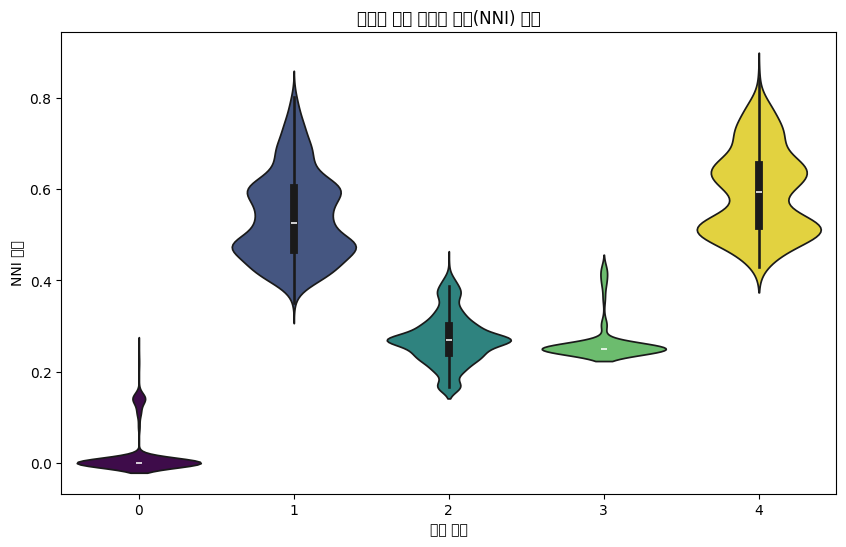

In [24]:
# 1. 군집별 NNI 분포
plt.figure(figsize=(10, 6))
sns.violinplot(x='kmeans_cluster', y='NNI', hue='kmeans_cluster', data=profiled, palette='viridis', legend=False)
plt.title('군집별 뉴스 유목민 지수(NNI) 분포')
plt.xlabel('군집 번호'); plt.ylabel('NNI 지수')
import os
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/군집별_NNI_분포_violin.png', dpi=150, bbox_inches='tight')
plt.show()

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


...

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


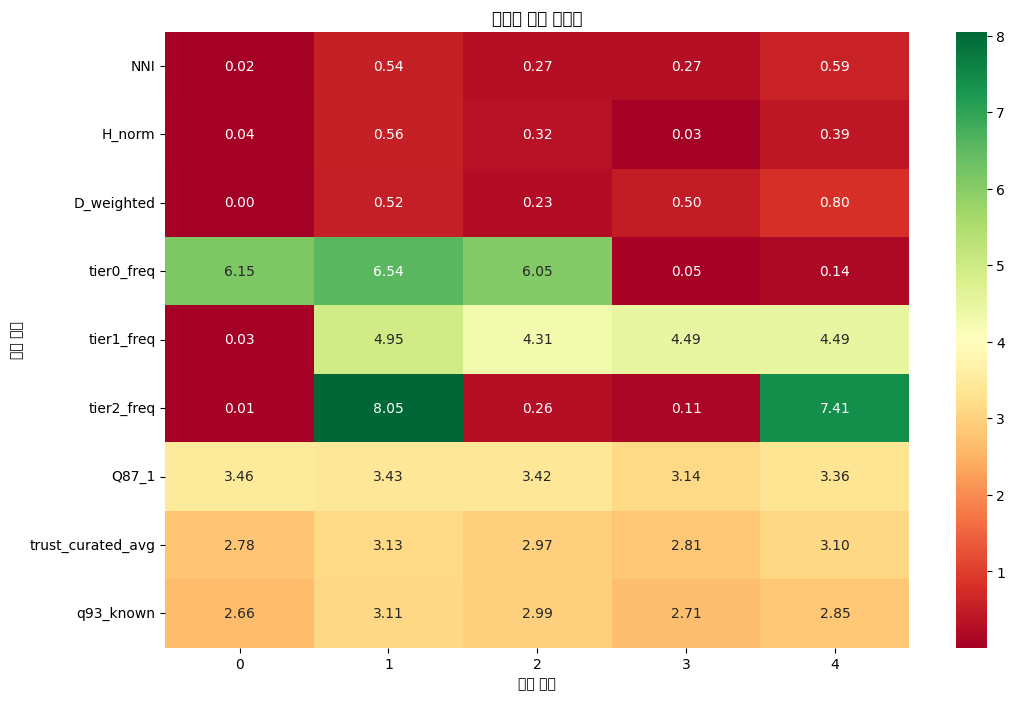

In [25]:
# 2. 군집별 변수 히트맵
plt.figure(figsize=(12, 8))
sns.heatmap(cluster_summary[summary_cols].T, annot=True, cmap='RdYlGn', fmt='.2f')
plt.title('군집별 특성 히트맵')
plt.xlabel('군집 번호'); plt.ylabel('분석 변수')
import os
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/군집별_특성_히트맵.png', dpi=150, bbox_inches='tight')
plt.show()

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


...

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


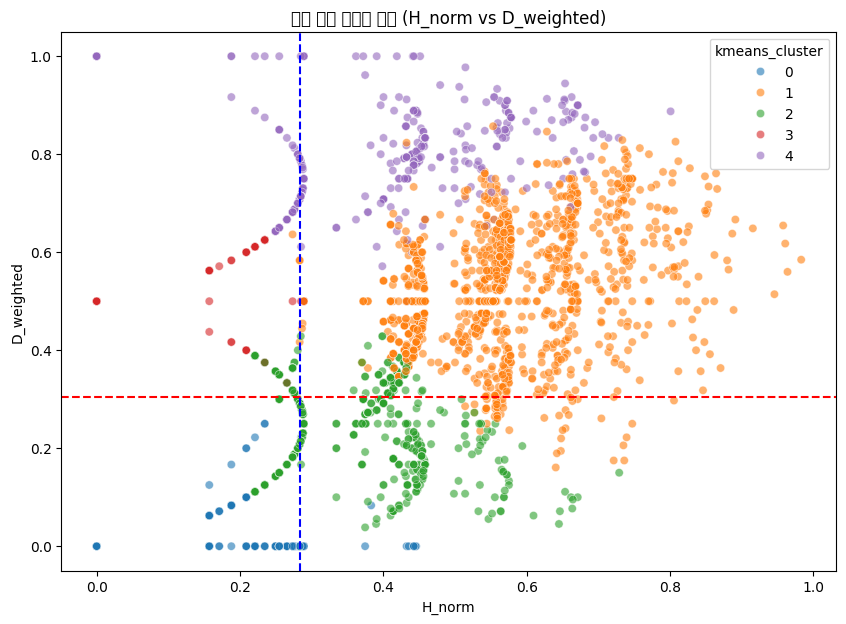

In [26]:
# 3. 뉴스 소비 생태계 지도 (H_norm vs D_weighted)
plt.figure(figsize=(10, 7))
sns.scatterplot(data=profiled, x='H_norm', y='D_weighted', hue='kmeans_cluster', palette='tab10', alpha=0.6)
plt.title('뉴스 소비 생태계 지도 (H_norm vs D_weighted)')
plt.axhline(profiled['D_weighted'].mean(), color='red', linestyle='--')
plt.axvline(profiled['H_norm'].mean(), color='blue', linestyle='--')
import os
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/뉴스소비_생태계지도.png', dpi=150, bbox_inches='tight')
plt.show()

## 15. 서비스 활용을 위한 모델 아티팩트 저장 + 실시간 채점 함수

학습된 scaler/kmeans/가중치를 저장해두면, 신규 이용자의 응답(채널별 최근 1주일 이용일수) 몇 개만으로
NNI 점수·백분위·유형을 즉시 계산하는 함수를 웹/앱 서비스 백엔드에 바로 이식할 수 있다.

In [27]:
# =========================================================
# 15-1. 아티팩트 저장
# =========================================================
ARTIFACT_DIR = 'nni_service_artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

artifacts = {
    'scaler': scaler,
    'kmeans': km,
    'cluster_features': cluster_features,
    'log_transform_cols': LOG_TRANSFORM_COLS,
    'freq_window': FREQ_WINDOW,
    'channel_specs': channel_specs,
    'H_max': H_max,
    'alpha': alpha,
    'beta': beta,
    'nni_reference_sorted': np.sort(df['NNI'].dropna().values),
    'cluster_name_map': cluster_name_map,
}
joblib.dump(artifacts, os.path.join(ARTIFACT_DIR, 'nni_artifacts.joblib'))
print('모델 아티팩트를', os.path.join(ARTIFACT_DIR, 'nni_artifacts.joblib'), '에 저장했습니다.')

모델 아티팩트를 nni_service_artifacts/nni_artifacts.joblib 에 저장했습니다.


In [28]:
# =========================================================
# 15-2. 신규 이용자 실시간 채점 함수
# =========================================================
# channel_days 형식: {channel_specs의 key: 최근 1주일 이용일수(평일+주말 합산, 0~7)}
# 일부 채널을 생략하면 자동으로 0(이용 안 함)으로 간주한다. 예) {'sns': 5, 'video': 4, 'portal': 2}
# 뉴스 채널 이용이 전혀 없으면 status='news_inactive'로 반환 (12절과 동일한 개념).

def score_new_user(channel_days, artifacts=artifacts):
    specs = artifacts['channel_specs']
    tiers = np.array([spec['tier'] for spec in specs.values()], dtype=float)
    keys = list(specs.keys())

    freq = np.array([float(channel_days.get(k, 0)) for k in keys])
    total = freq.sum()

    if total <= 0:
        return {'status': 'news_inactive',
                'message': '최근 1주일간 확인된 뉴스 채널 이용이 없어 지수를 계산할 수 없습니다.'}

    p = freq[freq > 0] / total
    H = -(p * np.log2(p)).sum()
    H_norm = H / artifacts['H_max']
    D_weighted = (freq * tiers).sum() / total / 2.0
    nni = artifacts['alpha'] * H_norm + artifacts['beta'] * D_weighted

    ref = artifacts['nni_reference_sorted']
    percentile = float(np.searchsorted(ref, nni) / len(ref) * 100)

    tier0 = freq[tiers == 0].sum(); tier1 = freq[tiers == 1].sum(); tier2 = freq[tiers == 2].sum()
    feat_row = pd.DataFrame([[H_norm, D_weighted, nni, tier0, tier1, tier2]], columns=artifacts['cluster_features'])
    for c in artifacts['log_transform_cols']:
        feat_row[c] = np.log1p(feat_row[c])

    X_new = artifacts['scaler'].transform(feat_row.values)
    cluster_id = int(artifacts['kmeans'].predict(X_new)[0])
    cluster_name = artifacts['cluster_name_map'].get(cluster_id, '군집' + str(cluster_id))

    return {'status': 'ok', 'NNI': round(float(nni), 4), 'NNI_percentile': round(percentile, 1),
            'H_norm': round(float(H_norm), 4), 'D_weighted': round(float(D_weighted), 4),
            'cluster_id': cluster_id, 'cluster_name': cluster_name,
            'tier0_freq': float(tier0), 'tier1_freq': float(tier1), 'tier2_freq': float(tier2)}

print(score_new_user({'sns': 5, 'video': 4, 'portal': 2}))

{'status': 'ok', 'NNI': 0.6706, 'NNI_percentile': 95.3, 'H_norm': 0.4321, 'D_weighted': 0.9091, 'cluster_id': 4, 'cluster_name': '디지털 유목민층', 'tier0_freq': 0.0, 'tier1_freq': 2.0, 'tier2_freq': 9.0}


## 16. 요약

- **실루엣 계수**: 로그변환 없이는 0.42\~0.43 수준이던 것이, tier0~2_freq에 log1p 변환을 적용하는
  것만으로 k=5 기준 **0.5535**까지 개선됨. 가중치(α,β)나 평일/주말 반영 범위는 실루엣에 거의
  영향을 주지 않았음(변동폭 0.01 이내) — 개선의 핵심은 "왜도가 큰 카운트 변수를 그대로 유클리드
  거리에 넣지 않는다"는 전처리 선택이었다.
- **구성타당도**: NNI 계산에 쓰지 않은 신뢰도·인지도·유료의향·연령과의 상관이 대부분 이론이
  예측하는 방향과 일치. Q93(언론사 인지)만 방향이 어긋나 tier 경계 재검토 여지로 남겨둠.
- **견고성**: 다중 시드 ARI=1.0(안정성), train/test 실루엣 격차 0.0003(일반화), NNI 포함/제외 시
  실루엣 차이 0.006(다중공선성 영향 미미) 모두 확인됨.
- **뉴스 비활성층(5.0%, n=298)**: 조용히 제외하지 않고 별도 세그먼트로 유지·분석함 (12절).
- **서비스 활용**: 학습된 전처리기/모델을 저장하고, 몇 개 문항만으로 즉시 채점하는 `score_new_user()`
  함수를 제공해 실제 웹/앱 서비스 백엔드로 바로 확장 가능한 구조를 마련함.
- **남은 한계**: 실루엣 0.55는 "군집이 어느 정도 분리된다"는 뜻이지 매우 뚜렷한 분리(통상 0.7 이상)는
  아니다. 

## 결과 파일 내보내기

제출용 `results/` 폴더 구성에 맞춰 군집 프로파일과 그리드서치 결과를 파일로 저장한다.

In [29]:
# =========================================================
# 결과 파일 내보내기 (results/ 폴더 구성용)
# =========================================================
os.makedirs('results', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

# 1) 군집 전체 프로파일
with pd.ExcelWriter(f'results/{optimal_k}군집_전체프로파일.xlsx') as writer:
    cluster_summary.to_excel(writer, sheet_name='군집_요약통계')
    df[['kmeans_cluster', 'cluster_name']].value_counts().sort_index()\
        .rename('n').reset_index().to_excel(writer, sheet_name='군집_이름_매핑', index=False)
print(f'저장 완료: results/{optimal_k}군집_전체프로파일.xlsx')

# 2) 그리드서치 전체 결과
alpha_k_grid.to_csv('results/그리드서치_전체결과.csv', index=False, encoding='utf-8-sig')
print('저장 완료: results/그리드서치_전체결과.csv')

저장 완료: results/5군집_전체프로파일.xlsx
저장 완료: results/그리드서치_전체결과.csv
